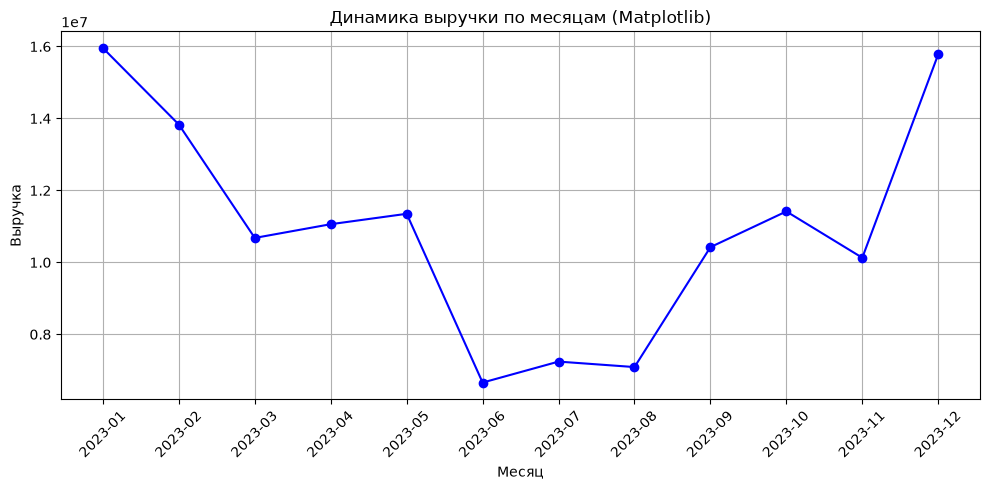

/var/folders/9f/0cwnm_691gx467dzl87mgw700000gn/T/ipykernel_8443/2149509972.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='category', y='revenue', estimator=sum, errorbar=None, palette='viridis')


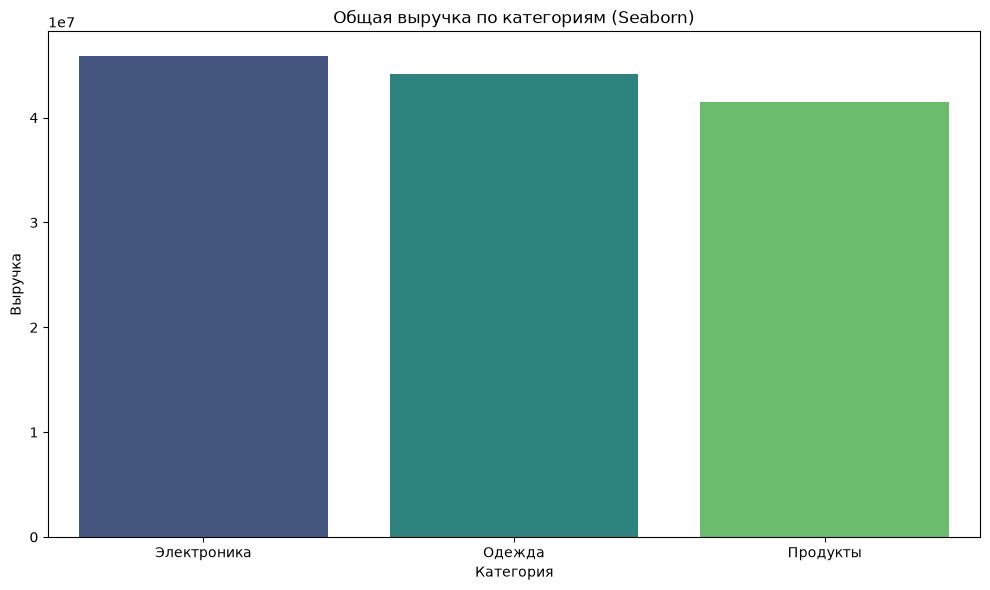

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

file_path = '/Users/pashok67/Desktop/SALES_ANALYSIS/part3_synthetic_data/data/sales.csv'
df = pd.read_csv(file_path)
df['date'] = pd.to_datetime(df['date'])
df['revenue'] = df['qty'] * df['price']

monthly_revenue = df.groupby(df['date'].dt.to_period('M'))['revenue'].sum().reset_index()
monthly_revenue['date'] = monthly_revenue['date'].astype(str)

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue['date'], monthly_revenue['revenue'], marker='o', color='b')
plt.title('Динамика выручки по месяцам (Matplotlib)')
plt.xlabel('Месяц')
plt.ylabel('Выручка')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('/Users/pashok67/Desktop/SALES_ANALYSIS/part3_synthetic_data/img_revenue_monthly.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='category', y='revenue', estimator=sum, errorbar=None, palette='viridis')
plt.title('Общая выручка по категориям (Seaborn)')
plt.xlabel('Категория')
plt.ylabel('Выручка')
plt.tight_layout()
plt.savefig('/Users/pashok67/Desktop/SALES_ANALYSIS/part3_synthetic_data/img_revenue_category.png')
plt.show()

promo_effect = df.groupby(['category', 'promo'])['qty'].mean().reset_index()
fig = px.bar(promo_effect, x='category', y='qty', color='promo', barmode='group',
             title='Влияние акций на среднее количество продаж (Plotly)',
             labels={'qty': 'Среднее количество', 'promo': 'Акция'})
fig.show()